In [1]:
import re, string, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import word_tokenize
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, classification_report)
warnings.filterwarnings("ignore")
for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4"]:
    nltk.download(pkg, quiet=True)

In [2]:
corpus = {
    "symptoms": [
        "What are the common symptoms of diabetes?",
        "I feel very thirsty all the time and urinate frequently",
        "Why am I always tired and hungry even after eating?",
        "What are the early warning signs of type 2 diabetes?",
        "Can blurred vision be a sign of diabetes?",
        "My wounds are healing very slowly, is it diabetes?",
        "Does frequent urination indicate high blood sugar?",
        "What symptoms appear when blood sugar is too low?",
        "What does high blood sugar feel like?",
        "Is increased hunger a symptom of diabetes?",
        "I have numbness and tingling in my hands, could it be diabetes?",
        "Why am I losing weight without trying?",
    ],
    "diagnosis_tests": [
        "What is the HbA1c test?",
        "How is diabetes diagnosed?",
        "What is a normal fasting blood glucose level?",
        "Which blood tests are done to confirm diabetes?",
        "What does an oral glucose tolerance test involve?",
        "What HbA1c value indicates prediabetes?",
        "How do doctors check whether I have diabetes?",
        "At what glucose level is a person considered diabetic?",
        "What is a normal HbA1c level?",
        "Do I need to fast before a diabetes blood test?",
        "What is a random blood glucose test?",
        "What are the screening tests for prediabetes?",
    ],
    "blood_sugar_monitoring": [
        "How often should I check my blood sugar?",
        "How do I use a glucometer?",
        "What is the best time to measure glucose levels?",
        "What is a continuous glucose monitor?",
        "What should my target blood sugar range be?",
        "How do I record my glucose readings?",
        "Should I test my sugar before or after meals?",
        "How can I measure my blood glucose at home?",
        "What is a healthy blood glucose reading after eating?",
        "How do I read my glucose meter results?",
        "How many times a day should I test my sugar?",
        "What is a good fasting sugar reading at home?",
    ],
    "complications": [
        "What complications can diabetes cause?",
        "How does diabetes affect the kidneys?",
        "Can diabetes damage my eyes?",
        "What is diabetic neuropathy?",
        "How can I prevent diabetic foot ulcers?",
        "Does diabetes increase the risk of heart disease?",
        "What is diabetic retinopathy?",
        "How do I protect my feet from diabetes problems?",
        "Can diabetes cause nerve damage?",
        "How does high sugar affect the heart and blood vessels?",
        "What is diabetic nephropathy?",
        "Can diabetes lead to amputation?",
    ],
    "medication": [
        "What does metformin do?",
        "What are the side effects of metformin?",
        "Which tablets are used to treat type 2 diabetes?",
        "Can I stop taking my diabetes pills when sugar is normal?",
        "What happens if I miss a dose of my diabetes medicine?",
        "How do oral anti-diabetic drugs work?",
        "Is it safe to take sulfonylurea tablets?",
        "What are GLP-1 medicines for diabetes?",
        "How does glipizide work?",
        "What is the best tablet for type 2 diabetes?",
        "Can diabetes medicines cause low blood sugar?",
        "When should I take my diabetes medicine, before or after food?",
    ],
    "insulin": [
        "What is insulin therapy?",
        "How do I inject insulin properly?",
        "Where on the body should I inject insulin?",
        "What are the different types of insulin?",
        "How should I store my insulin pens?",
        "What is the difference between rapid-acting and long-acting insulin?",
        "Why do I need insulin injections?",
        "How do insulin pumps work?",
        "How many types of insulin injections exist?",
        "What is basal and bolus insulin?",
        "How do I rotate insulin injection sites?",
        "Can type 2 diabetes patients need insulin?",
    ],
    "diet": [
        "What foods should a diabetic eat?",
        "Which foods should I avoid with diabetes?",
        "Can diabetics eat rice and fruits?",
        "What is a good diet plan for diabetes?",
        "How many carbohydrates should I eat per meal?",
        "Is sugar-free sweetener safe for diabetics?",
        "What is the glycemic index of foods?",
        "Can I drink fruit juice if I have diabetes?",
        "Are bananas and mangoes safe for diabetics?",
        "What is the best breakfast for a diabetic?",
        "Should I count carbs while eating?",
        "Can diabetics have sweets or desserts?",
    ],
    "exercise_lifestyle": [
        "What exercises are good for diabetes?",
        "How much physical activity do I need each week?",
        "Does walking after meals lower blood sugar?",
        "How does stress affect blood sugar?",
        "Can losing weight reverse type 2 diabetes?",
        "Is yoga helpful for diabetes control?",
        "How does sleep affect diabetes?",
        "Should I stop smoking and alcohol to manage diabetes?",
        "How long should I walk daily to control diabetes?",
        "Is it safe to do weight training with diabetes?",
        "What lifestyle changes help prevent type 2 diabetes?",
        "Does drinking alcohol affect my blood sugar?",
    ],
}

queries, labels = [], []
for intent, qs in corpus.items():
    for q in qs:
        queries.append(q)
        labels.append(intent)

df = pd.DataFrame({"query": queries, "intent": labels})
print("Total queries :", len(df))
print("Intent count  :", df['intent'].nunique())
print(df['intent'].value_counts())

Total queries : 96
Intent count  : 8
intent
symptoms                  12
diagnosis_tests           12
blood_sugar_monitoring    12
complications             12
medication                12
insulin                   12
diet                      12
exercise_lifestyle        12
Name: count, dtype: int64


In [3]:
taxonomy = {
    "Clinical Information":       ["symptoms", "diagnosis_tests"],
    "Monitoring & Complications": ["blood_sugar_monitoring", "complications"],
    "Treatment":                  ["medication", "insulin"],
    "Lifestyle Management":       ["diet", "exercise_lifestyle"],
}
for category, subs in taxonomy.items():
    print(category)
    for s in subs:
        print("   └──", s)
intent_to_category = {s: c for c, subs in taxonomy.items() for s in subs}

Clinical Information
   └── symptoms
   └── diagnosis_tests
Monitoring & Complications
   └── blood_sugar_monitoring
   └── complications
Treatment
   └── medication
   └── insulin
Lifestyle Management
   └── diet
   └── exercise_lifestyle


In [4]:
ontology = {
    "Patient":       {"has": "Diabetes", "experiences": "Symptoms", "monitors": "Blood Glucose",
                      "follows": "Diet", "performs": "Exercise", "takes": "Medication"},
    "Diabetes":      {"shows": "Symptoms", "diagnosed_by": "HbA1c Test",
                      "causes": "Complications", "controlled_by": "Medication"},
    "Medication":    {"includes": "Insulin", "lowers": "Blood Glucose"},
    "Insulin":       {"regulates": "Blood Glucose"},
    "Diet":          {"affects": "Blood Glucose"},
    "Exercise":      {"improves": "Insulin Sensitivity"},
    "HbA1c Test":    {"measures": "Blood Glucose"},
    "Complications": {"include": "Neuropathy"},
}
concepts = set(ontology.keys())
for rels in ontology.values():
    concepts.update(rels.values())
print("Number of concepts:", len(concepts))
print(sorted(concepts))

rel_count = 0
print("\nRelationships:")
for subj, rels in ontology.items():
    for rel, obj in rels.items():
        print(f"  {subj} --{rel}--> {obj}")
        rel_count += 1
print("\nNumber of relationships:", rel_count)

intent_to_concept = {
    "symptoms": "Symptoms", "diagnosis_tests": "HbA1c Test",
    "blood_sugar_monitoring": "Blood Glucose", "complications": "Complications",
    "medication": "Medication", "insulin": "Insulin",
    "diet": "Diet", "exercise_lifestyle": "Exercise",
}

Number of concepts: 12
['Blood Glucose', 'Complications', 'Diabetes', 'Diet', 'Exercise', 'HbA1c Test', 'Insulin', 'Insulin Sensitivity', 'Medication', 'Neuropathy', 'Patient', 'Symptoms']

Relationships:
  Patient --has--> Diabetes
  Patient --experiences--> Symptoms
  Patient --monitors--> Blood Glucose
  Patient --follows--> Diet
  Patient --performs--> Exercise
  Patient --takes--> Medication
  Diabetes --shows--> Symptoms
  Diabetes --diagnosed_by--> HbA1c Test
  Diabetes --causes--> Complications
  Diabetes --controlled_by--> Medication
  Medication --includes--> Insulin
  Medication --lowers--> Blood Glucose
  Insulin --regulates--> Blood Glucose
  Diet --affects--> Blood Glucose
  Exercise --improves--> Insulin Sensitivity
  HbA1c Test --measures--> Blood Glucose
  Complications --include--> Neuropathy

Number of relationships: 17


In [5]:
ontology = {
    "Patient":       {"has": "Diabetes", "experiences": "Symptoms", "monitors": "Blood Glucose",
                      "follows": "Diet", "performs": "Exercise", "takes": "Medication"},
    "Diabetes":      {"shows": "Symptoms", "diagnosed_by": "HbA1c Test",
                      "causes": "Complications", "controlled_by": "Medication"},
    "Medication":    {"includes": "Insulin", "lowers": "Blood Glucose"},
    "Insulin":       {"regulates": "Blood Glucose"},
    "Diet":          {"affects": "Blood Glucose"},
    "Exercise":      {"improves": "Insulin Sensitivity"},
    "HbA1c Test":    {"measures": "Blood Glucose"},
    "Complications": {"include": "Neuropathy"},
}
concepts = set(ontology.keys())
for rels in ontology.values():
    concepts.update(rels.values())
print("Number of concepts:", len(concepts))
print(sorted(concepts))

rel_count = 0
print("\nRelationships:")
for subj, rels in ontology.items():
    for rel, obj in rels.items():
        print(f"  {subj} --{rel}--> {obj}")
        rel_count += 1
print("\nNumber of relationships:", rel_count)

intent_to_concept = {
    "symptoms": "Symptoms", "diagnosis_tests": "HbA1c Test",
    "blood_sugar_monitoring": "Blood Glucose", "complications": "Complications",
    "medication": "Medication", "insulin": "Insulin",
    "diet": "Diet", "exercise_lifestyle": "Exercise",
}

Number of concepts: 12
['Blood Glucose', 'Complications', 'Diabetes', 'Diet', 'Exercise', 'HbA1c Test', 'Insulin', 'Insulin Sensitivity', 'Medication', 'Neuropathy', 'Patient', 'Symptoms']

Relationships:
  Patient --has--> Diabetes
  Patient --experiences--> Symptoms
  Patient --monitors--> Blood Glucose
  Patient --follows--> Diet
  Patient --performs--> Exercise
  Patient --takes--> Medication
  Diabetes --shows--> Symptoms
  Diabetes --diagnosed_by--> HbA1c Test
  Diabetes --causes--> Complications
  Diabetes --controlled_by--> Medication
  Medication --includes--> Insulin
  Medication --lowers--> Blood Glucose
  Insulin --regulates--> Blood Glucose
  Diet --affects--> Blood Glucose
  Exercise --improves--> Insulin Sensitivity
  HbA1c Test --measures--> Blood Glucose
  Complications --include--> Neuropathy

Number of relationships: 17


In [6]:
stop_words = set(stopwords.words("english"))
lemmatizer = WordNetLemmatizer()

def preprocess(text):
    text = text.lower()
    text = text.translate(str.maketrans("", "", string.punctuation.replace("-", "")))
    text = text.replace("-", " ")
    tokens = word_tokenize(text)
    tokens = [t for t in tokens if t not in stop_words]
    tokens = [lemmatizer.lemmatize(lemmatizer.lemmatize(t, "v"), "n")
              for t in tokens]
    return " ".join(tokens)

for q in ["What are the side effects of metformin?", "How do insulin pumps work?"]:
    print(q, "->", preprocess(q))

df["clean"] = df["query"].apply(preprocess)
df.head()

What are the side effects of metformin? -> side effect metformin
How do insulin pumps work? -> insulin pump work


,query,intent,clean
0,What are the common symptoms of diabetes?,symptoms,common symptom diabetes
1,I feel very thirsty all the time and urinate f...,symptoms,feel thirsty time urinate frequently
2,Why am I always tired and hungry even after ea...,symptoms,always tire hungry even eat
3,What are the early warning signs of type 2 dia...,symptoms,early warn sign type 2 diabetes
4,Can blurred vision be a sign of diabetes?,symptoms,blur vision sign diabetes


In [7]:
X_train_txt, X_test_txt, y_train, y_test = train_test_split(
    df["clean"], df["intent"], test_size=0.25, random_state=42, stratify=df["intent"])

vectorizer = TfidfVectorizer()
X_train = vectorizer.fit_transform(X_train_txt)
X_test = vectorizer.transform(X_test_txt)
print("TF-IDF shape (train):", X_train.shape)

model = LogisticRegression(C=50, max_iter=1000)
model.fit(X_train, y_train)

TF-IDF shape (train): (72, 155)


LogisticRegression(C=50, max_iter=1000)

Accuracy  : 0.667
Precision : 0.758
Recall    : 0.667
F1-score  : 0.657

Classification report:

                        precision    recall  f1-score   support

blood_sugar_monitoring       0.50      0.67      0.57         3
         complications       0.67      0.67      0.67         3
       diagnosis_tests       0.75      1.00      0.86         3
                  diet       1.00      0.67      0.80         3
    exercise_lifestyle       0.40      0.67      0.50         3
               insulin       0.75      1.00      0.86         3
            medication       1.00      0.33      0.50         3
              symptoms       1.00      0.33      0.50         3

              accuracy                           0.67        24
             macro avg       0.76      0.67      0.66        24
          weighted avg       0.76      0.67      0.66        24



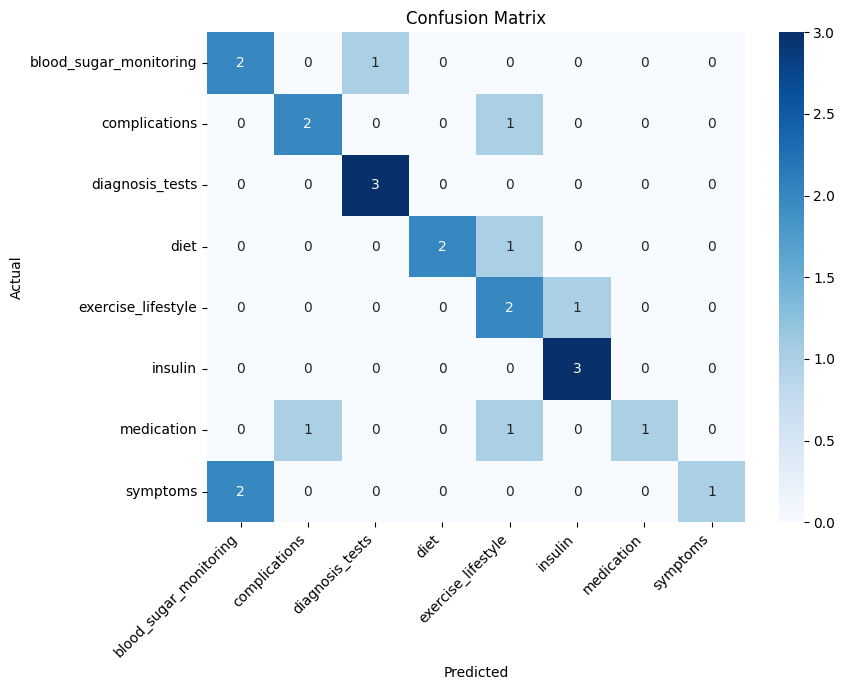

LogisticRegression(C=50, max_iter=1000)

In [8]:
y_pred = model.predict(X_test)
print("Accuracy  :", round(accuracy_score(y_test, y_pred), 3))
print("Precision :", round(precision_score(y_test, y_pred, average="weighted", zero_division=0), 3))
print("Recall    :", round(recall_score(y_test, y_pred, average="weighted", zero_division=0), 3))
print("F1-score  :", round(f1_score(y_test, y_pred, average="weighted", zero_division=0), 3))
print("\nClassification report:\n")
print(classification_report(y_test, y_pred, zero_division=0))

class_names = model.classes_
cm = confusion_matrix(y_test, y_pred, labels=class_names)
plt.figure(figsize=(9, 7))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.title("Confusion Matrix")
plt.xticks(rotation=45, ha="right"); plt.tight_layout()
plt.show()

X_all = vectorizer.fit_transform(df["clean"])
model.fit(X_all, df["intent"])

In [11]:
knowledge_base = {
    "symptoms": "Common symptoms of diabetes include increased thirst, frequent urination, extreme hunger, unexplained weight loss, fatigue, blurred vision, slow-healing wounds and frequent infections. Type 1 symptoms often appear suddenly, while type 2 symptoms develop gradually and may go unnoticed for years.",
    "diagnosis_tests": "Diabetes is diagnosed with blood tests: Fasting Plasma Glucose (>=126 mg/dL), HbA1c (>=6.5%), Oral Glucose Tolerance Test (2-hour value >=200 mg/dL) or a random glucose >=200 mg/dL with symptoms. HbA1c of 5.7-6.4% or fasting glucose of 100-125 mg/dL indicates prediabetes.",
    "blood_sugar_monitoring": "Blood sugar is checked with a glucometer (finger-prick) or a continuous glucose monitor (CGM). Common targets are 80-130 mg/dL before meals and below 180 mg/dL two hours after meals, but your doctor will set your personal range. Keep a log of readings and share it with your care team.",
    "complications": "Long-term high blood sugar can damage the eyes (retinopathy), kidneys (nephropathy), nerves (neuropathy) and blood vessels, raising the risk of heart disease, stroke and foot ulcers. Prevention: keep HbA1c in range, control blood pressure and cholesterol, inspect your feet daily, and have yearly eye, kidney and foot check-ups.",
    "medication": "Metformin is the usual first-line tablet for type 2 diabetes; it reduces glucose production in the liver. Other drug groups include sulfonylureas, DPP-4 inhibitors, SGLT2 inhibitors and GLP-1 agonists. Take medicines exactly as prescribed, never stop them on your own, and ask your doctor or pharmacist about a missed dose or side effects.",
    "insulin": "Insulin replaces or supplements the body's own insulin. Types include rapid-acting, short-acting, intermediate-acting and long-acting. It is injected into the fatty tissue of the abdomen, thigh or upper arm, rotating sites each time. Unopened insulin is stored in a refrigerator; the in-use pen is kept at room temperature as per its label. Your doctor decides the type and dose.",
    "diet": "A diabetes-friendly diet focuses on whole grains, vegetables, legumes, lean protein and healthy fats, with controlled portions of carbohydrates and fruits. Limit sugary drinks, sweets, refined flour and fried foods. Choose low glycemic-index foods and keep regular meal timings. A dietitian can create a personalised plan.",
    "exercise_lifestyle": "Aim for at least 150 minutes of moderate activity a week (e.g. brisk walking) plus muscle-strengthening exercise on 2 days. A short walk after meals helps lower blood sugar. Maintain a healthy weight, manage stress, sleep 7-8 hours, avoid smoking and limit alcohol.",
}

emergency_response = ("EMERGENCY WARNING: Your message describes possible signs of a diabetic emergency "
                      "(severe low/high blood sugar or DKA). Call your local emergency number (112 / 108 in India) "
                      "or go to the nearest hospital IMMEDIATELY. If the person is conscious and has low blood sugar, "
                      "give 15 g of fast-acting sugar (glucose tablets or juice) while waiting for help.")
DISCLAIMER = "\n\n This is general information only, not a substitute for professional medical advice."

In [12]:
EMERGENCY_KEYWORDS = [
    "unconscious", "passed out", "fainted", "not responding", "seizure", "convulsion",
    "fruity breath", "difficulty breathing", "cant breathe", "can't breathe", "chest pain",
    "severe vomiting", "vomiting and", "very confused", "cannot wake", "can't wake",
    "emergency", "dka", "ketoacidosis", "coma", "blood sugar is 40", "blood sugar 40",
]
UNSUPPORTED_HEALTH_KEYWORDS = [
    "cancer", "fracture", "broken", "asthma", "covid", "fever", "headache", "migraine",
    "pregnan", "dengue", "malaria", "tooth", "dental", "skin rash", "acne", "hair fall",
    "thyroid", "kidney stone", "arthritis", "depression", "anxiety", "eczema", "cold and cough",
]
DOSAGE_PATTERNS = ["how much insulin", "how many units", "dose of", "dosage", "how many tablets",
                   "how many pills", "how much metformin"]
GREETINGS = ["hi", "hello", "hey", "good morning", "good evening", "namaste"]
EXITS = ["bye", "exit", "quit", "goodbye", "thank you", "thanks"]
CONFIDENCE_THRESHOLD = 0.35
domain_vocab = set(" ".join(df["clean"]).split())

In [13]:
def classify_intent(query):
    clean = preprocess(query)
    vec = vectorizer.transform([clean])
    probs = model.predict_proba(vec)[0]
    idx = int(np.argmax(probs))
    return model.classes_[idx], float(probs[idx]), clean

def assistant(query):
    q = query.lower().strip()

    if any(k in q for k in EMERGENCY_KEYWORDS):
        return {"rule": "R1: Emergency escalation", "intent": "emergency",
                "confidence": 1.0, "response": emergency_response}

    if q in GREETINGS or any(q.startswith(g + " ") for g in GREETINGS):
        return {"rule": "R2: Greeting", "intent": "greeting", "confidence": 1.0,
                "response": "Hello! I am the Diabetes Care Information Assistant. Ask me about symptoms, tests, blood sugar monitoring, complications, medicines, insulin, diet or exercise."}
    if any(w in q for w in EXITS):
        return {"rule": "R2: Farewell", "intent": "farewell", "confidence": 1.0,
                "response": "You're welcome! Take care and stay healthy. 👋"}

    if any(k in q for k in UNSUPPORTED_HEALTH_KEYWORDS):
        return {"rule": "R3: Unsupported healthcare query", "intent": "unsupported", "confidence": 1.0,
                "response": "I can only answer questions about diabetes care. For other health problems please consult a qualified doctor."}

    intent, conf, clean = classify_intent(query)
    if not any(tok in domain_vocab for tok in clean.split()):
        return {"rule": "R4: Out-of-domain query", "intent": "unsupported", "confidence": conf,
                "response": "Sorry, I can only help with diabetes-related questions."}

    if conf < CONFIDENCE_THRESHOLD:
        return {"rule": "R5: Low confidence", "intent": intent, "confidence": conf,
                "response": "I'm not sure I understood that. Could you rephrase your question? You can ask about diabetes symptoms, tests, glucose monitoring, complications, medicines, insulin, diet or exercise."}

    if any(p in q for p in DOSAGE_PATTERNS):
        return {"rule": "R6: Dosage safety", "intent": intent, "confidence": conf,
                "response": "I cannot suggest medicine or insulin doses. The dose depends on your weight, glucose readings and other conditions - please consult your doctor or diabetes educator." + DISCLAIMER}

    answer = knowledge_base[intent]
    concept = intent_to_concept[intent]
    related = [f"{concept} --{r}--> {o}" for r, o in ontology.get(concept, {}).items()]
    extra = ("\n\n🔗 Related concepts: " + "; ".join(related)) if related else ""
    return {"rule": "Normal: ML intent + knowledge retrieval", "intent": intent,
            "confidence": conf, "response": answer + extra + DISCLAIMER}

In [14]:
import ipywidgets as widgets
from IPython.display import display, clear_output

box = widgets.Text(placeholder="Ask a diabetes-related question...", layout=widgets.Layout(width="70%"))
send = widgets.Button(description="Send", button_style="primary")
reset = widgets.Button(description="Clear chat")
out = widgets.Output()

def on_send(_):
    q = box.value.strip()
    if not q:
        return
    r = assistant(q)
    with out:
        print(f"🧑 You      : {q}")
        print(f"🤖 Assistant: {r['response']}")
        cat = intent_to_category.get(r['intent'], "-")
        print(f"   [intent={r['intent']} | category={cat} | confidence={r['confidence']:.2f} | {r['rule']}]\n")
    box.value = ""

def on_reset(_):
    with out:
        clear_output()

send.on_click(on_send)
box.on_submit(on_send)
reset.on_click(on_reset)

print("🩺 Diabetes Care Information Assistant: type a question and press Send / Enter.")
display(widgets.HBox([box, send, reset]), out)

🩺 Diabetes Care Information Assistant: type a question and press Send / Enter.


Output()

In [15]:
tests = [
    ("Intent: symptoms",        "What are the signs of diabetes?"),
    ("Intent: diagnosis_tests", "How is diabetes confirmed with a blood test?"),
    ("Intent: monitoring",      "How often should I test my glucose?"),
    ("Intent: complications",   "Can diabetes harm my kidneys?"),
    ("Intent: medication",      "Tell me about metformin tablets"),
    ("Intent: insulin",         "How do I take insulin injections?"),
    ("Intent: diet",            "What should I eat if I have diabetes?"),
    ("Intent: exercise",        "Is walking good for sugar control?"),
    ("Differently worded",      "Why do I keep running to the toilet and feel so thirsty?"),
    ("Unsupported healthcare",  "How do I treat a broken arm?"),
    ("Out-of-domain",           "Who won the cricket world cup?"),
    ("Low confidence",          "Is diabetes serious?"),
    ("Emergency",               "My father with diabetes is unconscious and not responding"),
    ("Dosage safety",           "How much insulin should I take?"),
]
for title, q in tests:
    r = assistant(q)
    print(f"[{title}] {q}")
    print(f"   -> intent={r['intent']}, conf={r['confidence']:.2f}, rule={r['rule']}")
    print("   ", r['response'][:110].replace("\n", " "), "...\n")

[Intent: symptoms] What are the signs of diabetes?
   -> intent=symptoms, conf=0.87, rule=Normal: ML intent + knowledge retrieval
    Common symptoms of diabetes include increased thirst, frequent urination, extreme hunger, unexplained weight l ...

[Intent: diagnosis_tests] How is diabetes confirmed with a blood test?
   -> intent=diagnosis_tests, conf=0.94, rule=Normal: ML intent + knowledge retrieval
    Diabetes is diagnosed with blood tests: Fasting Plasma Glucose (>=126 mg/dL), HbA1c (>=6.5%), Oral Glucose Tol ...

[Intent: monitoring] How often should I test my glucose?
   -> intent=blood_sugar_monitoring, conf=0.80, rule=Normal: ML intent + knowledge retrieval
    Blood sugar is checked with a glucometer (finger-prick) or a continuous glucose monitor (CGM). Common targets  ...

[Intent: complications] Can diabetes harm my kidneys?
   -> intent=complications, conf=0.87, rule=Normal: ML intent + knowledge retrieval
    Long-term high blood sugar can damage the eyes (retinopathy),